Course: AI3301 - Data Analysis & Visualization

Members:



1.   Maryam Ajabnoor - Leader
2.   Manar Bawadood
3.   Somayah Alkhateeb
4.   Selma Chelbabi
5.   Aljawharah Alsaadi








# Assignment #1

# Proplem Definition

The dataset(Student Performance) was provided by our lecturer Prof.Omniah H.Nagoor
This project aims to analyse and find the relationships between the average score and the features as well as to answer whether the demographic and preparation factors influence the students academic performance.

# Hypotheses

H1: Does test preparation course affect very positively in the average score?

H2: Does the educational level of parents has an influnce in students grades?

H3: How strongly does the race/ethnicity play a role in the average score?


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns

#  Discover the Dataset - Maryam Ajabnoor

In [ ]:
df = pd.read_csv("https://drive.google.com/uc?id=18e-MGZT0g-oHJXG5Dotrhtv-XOfrKb_F")

df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72.0,72.0,74.0
1,female,group C,some college,standard,completed,69.0,90.0,88.0
2,female,group B,master's degree,standard,none,90.0,95.0,93.0
3,male,group A,associate's degree,free/reduced,none,47.0,57.0,44.0
4,male,group C,some college,standard,none,76.0,NaN,75.0


In [ ]:
print(f'The Shape: {df.shape}')
df.info()


The Shape: (1000, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   gender                       1000 non-null   object 
 1   race/ethnicity               1000 non-null   object 
 2   parental level of education  1000 non-null   object 
 3   lunch                        971 non-null    object 
 4   test preparation course      1000 non-null   object 
 5   math score                   997 non-null    float64
 6   reading score                997 non-null    float64
 7   writing score                997 non-null    float64
dtypes: float64(3), object(5)
memory usage: 62.6+ KB


In [ ]:

df.describe()


,math score,reading score,writing score
count,997.000000,997.000000,997.000000
mean,66.078235,68.987964,68.002006
std,15.322893,15.556538,15.409992
min,-10.000000,-99.000000,-10.000000
25%,57.000000,59.000000,57.000000
50%,66.000000,70.000000,69.000000
75%,77.000000,79.000000,79.000000
max,100.000000,100.000000,100.000000


In [ ]:

df.describe(include='object')

,gender,race/ethnicity,parental level of education,lunch,test preparation course
count,1000,1000,1000,971,1000
unique,2,5,6,2,4
top,female,group C,some college,standard,none
freq,518,319,226,629,638


In [ ]:
for c in df.select_dtypes("object"):
    print(f"\n{c}:\n", df[c].value_counts(dropna=False))


gender:
 gender
female    518
male      482
Name: count, dtype: int64

race/ethnicity:
 race/ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64

parental level of education:
 parental level of education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64

lunch:
 lunch
standard        629
free/reduced    342
NaN              29
Name: count, dtype: int64

test preparation course:
 test preparation course
none         638
completed    348
1             10
0              4
Name: count, dtype: int64


**Important Notes**



*   Scores values are not correct ``` min= -99/-10```, with 3 records missing their values.


*   ```lunch``` column has some missing values

* There are 5 categorical columns need to be encode, with special handling for ```test preparation course``` column.   



# Cleannig - Manar Bawadood




In [ ]:

cat_cols   = ["gender", "race/ethnicity", "parental level of education", "lunch", "test preparation course"]
score_cols = ["math score", "reading score", "writing score"]


In [ ]:

df_clean=df.copy()

for col in score_cols:
    df_clean[col] = df_clean[col].replace(-99, np.nan)
    df_clean[col] = df_clean[col].replace(-10, np.nan)

df_clean.describe()

,math score,reading score,writing score
count,996.000000,996.000000,996.000000
mean,66.154618,69.156627,68.080321
std,15.139492,14.623914,15.217934
min,0.000000,17.000000,10.000000
25%,57.000000,59.000000,57.750000
50%,66.000000,70.000000,69.000000
75%,77.000000,79.250000,79.000000
max,100.000000,100.000000,100.000000




> Now score culomns are in proper range (from 0 to 100) with no negative values.



In [ ]:
# Missing value audit
missing = pd.DataFrame({
    "n_missing": df_clean.isna().sum(),
    "pct_missing": (df_clean.isna().mean() * 100).round(2)
}).sort_values("pct_missing", ascending=False)
print(missing)

                             n_missing  pct_missing
lunch                               29          2.9
writing score                        4          0.4
reading score                        4          0.4
math score                           4          0.4
parental level of education          0          0.0
race/ethnicity                       0          0.0
gender                               0          0.0
test preparation course              0          0.0


In [ ]:

tp_map = {"none": "none", "completed": "completed",
          "0": "none", "1": "completed"}

df_clean['test preparation course'] = (
    df_clean['test preparation course'].astype("string").str.strip().str.lower().map(tp_map))
print(df_clean['test preparation course'].value_counts()) # expect none=642, completed=358

test preparation course
none         642
completed    358
Name: count, dtype: int64


In [ ]:
for col in score_cols:
    group_median = df_clean.groupby(df_clean["test preparation course"], observed=True)[col].transform("median")
    df_clean[col] = df_clean[col].fillna(group_median).fillna(df_clean[col].median())   # fallback: overall median


df_clean['lunch']= df_clean['lunch'].fillna(df_clean["lunch"].mode()[0])
print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())


Missing values after cleaning:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64




> We filled score columns with median by grouping the ```test preparation course ``` values.


>  ```lunch``` column was filles with mode and we did not group it.





In [ ]:
df_clean.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72.0,72.0,74.0
1,female,group C,some college,standard,completed,69.0,90.0,88.0
2,female,group B,master's degree,standard,none,90.0,95.0,93.0
3,male,group A,associate's degree,free/reduced,none,47.0,57.0,44.0
4,male,group C,some college,standard,none,76.0,67.0,75.0


In [ ]:
print(f"Rows involved in duplication: {df_clean.duplicated().sum()}")

Rows involved in duplication: 0




> There are no duplicated values



# Detection Outliers- Somayah Alkhateeb



*   We found out that the outliers present in the score columns turned out to be less than 1 percent.




In [ ]:
# 3. IQR-based outlier bounds for 'reading score'
q1 = df_clean["reading score"].quantile(0.25)
q3 = df_clean["reading score"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

n_outliers = ((df_clean["reading score"] < lower_bound) | (df_clean["reading score"] > upper_bound)).sum()
print(f"IQR bounds: [{lower_bound:.3f}, {upper_bound:.3f}]")
print(f"Outliers flagged: {n_outliers} ({n_outliers/len(df_clean):.2%} of data)")

IQR bounds: [29.000, 109.000]
Outliers flagged: 6 (0.60% of data)


In [ ]:
q1 = df_clean["writing score"].quantile(0.25)
q3 = df_clean["writing score"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

n_outliers = ((df_clean["writing score"] < lower_bound) | (df_clean["writing score"] > upper_bound)).sum()
print(f"IQR bounds: [{lower_bound:.3f}, {upper_bound:.3f}]")
print(f"Outliers flagged: {n_outliers} ({n_outliers/len(df_clean):.2%} of data)")

IQR bounds: [26.500, 110.500]
Outliers flagged: 5 (0.50% of data)


In [ ]:
q1 = df_clean["math score"].quantile(0.25)
q3 = df_clean["math score"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

n_outliers = ((df_clean["math score"] < lower_bound) | (df_clean["math score"] > upper_bound)).sum()
print(f"IQR bounds: [{lower_bound:.3f}, {upper_bound:.3f}]")
print(f"Outliers flagged: {n_outliers} ({n_outliers/len(df_clean):.2%} of data)")

IQR bounds: [27.000, 107.000]
Outliers flagged: 8 (0.80% of data)




> We will keep the outliers as they represent real scores for week students, removing them would bias the distribution.



# Transformation - Maryam Ajabnoor

In [ ]:
df_clean["average score"] = df_clean[score_cols].mean(axis=1)
df_clean.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,average score
0,female,group B,bachelor's degree,standard,none,72.0,72.0,74.0,72.666667
1,female,group C,some college,standard,completed,69.0,90.0,88.0,82.333333
2,female,group B,master's degree,standard,none,90.0,95.0,93.0,92.666667
3,male,group A,associate's degree,free/reduced,none,47.0,57.0,44.0,49.333333
4,male,group C,some college,standard,none,76.0,67.0,75.0,72.666667




> We`ve derived new column from all the scores to represent the average score for the individsual.

- We don't need to transform to lomg format becuse


# Encoding and Scalling -Selma Chelbabi





In [ ]:
# Encoding: keep df_clean as readable text (for plots), encode a separate copy (for statistics)
df_encoded = df_clean.copy()

# 1) Binary features -> explicit 0/1 mapping
binary_maps = {
    "gender": {"female": 0, "male": 1},
    "lunch": {"free/reduced": 0, "standard": 1},
    "test preparation course": {"none": 0, "completed": 1},
}
for col, mapping in binary_maps.items():
    df_encoded[col] = df_encoded[col].map(mapping)

# 2) Ordinal feature -> rank from lowest (0) to highest (5) education level
edu_order = ["some high school", "high school", "some college",
             "associate's degree", "bachelor's degree", "master's degree"]
edu_map = {level: rank for rank, level in enumerate(edu_order)}
df_encoded["parental level of education"] = df_encoded["parental level of education"].map(edu_map)

# 3) Nominal feature -> one-hot columns (no false order between groups)
df_encoded = pd.get_dummies(df_encoded, columns=["race/ethnicity"], dtype=int)

# Check: any label that did not match its mapping becomes NaN
print("Unmapped values:", df_encoded.isna().sum().sum())
df_encoded.head()

Unmapped values: 0


,gender,parental level of education,lunch,test preparation course,math score,reading score,writing score,average score,race/ethnicity_group A,race/ethnicity_group B,race/ethnicity_group C,race/ethnicity_group D,race/ethnicity_group E
0,0,4,1,0,72.0,72.0,74.0,72.666667,0,1,0,0,0
1,0,2,1,1,69.0,90.0,88.0,82.333333,0,0,1,0,0
2,0,5,1,0,90.0,95.0,93.0,92.666667,0,1,0,0,0
3,1,3,0,0,47.0,57.0,44.0,49.333333,1,0,0,0,0
4,1,2,1,0,76.0,67.0,75.0,72.666667,0,0,1,0,0




- Label Encoding was applied to convert categorical features into numeric integer representations which is necessary to perform numeric operations across all features.

-  A scaler wasn't used because all numeric score features fall into a close range of values(0-100 points) and so there will not be a feature dominance issue.



#   Visualization -Aljawharah Alsaadi




<Axes: xlabel='writing score'>

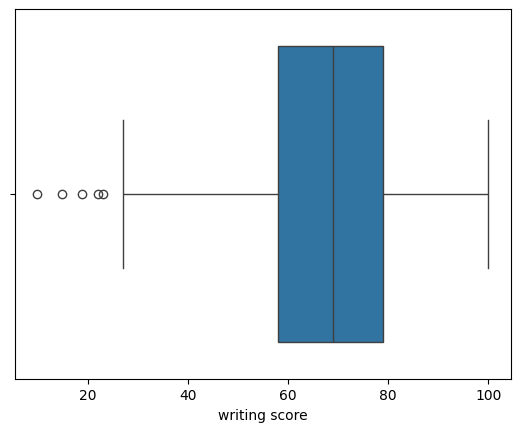

In [ ]:
# @title
sns.boxplot(x=df_clean["writing score"])


<Axes: xlabel='math score'>

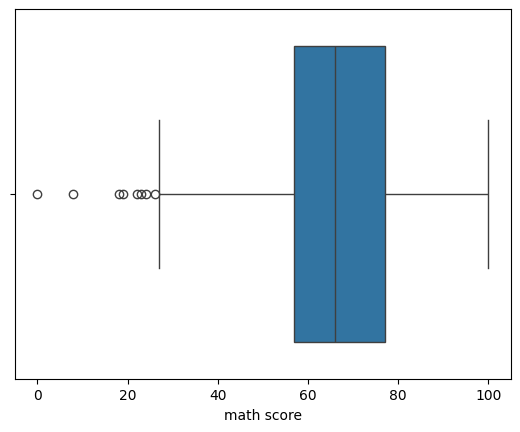

In [ ]:
# @title
sns.boxplot(x=df_clean["math score"])

<Axes: xlabel='reading score'>

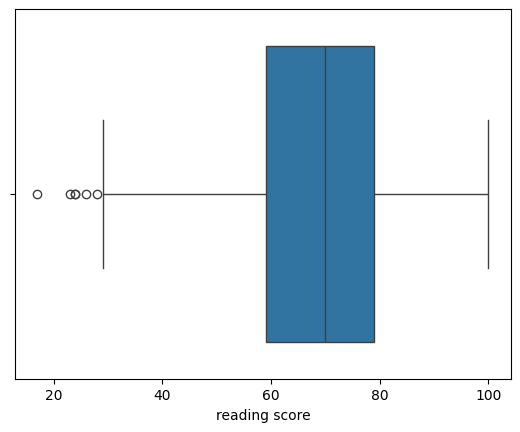

In [ ]:
# @title
sns.boxplot(x=df_clean["reading score"])

<Axes: xlabel='gender', ylabel='average score'>

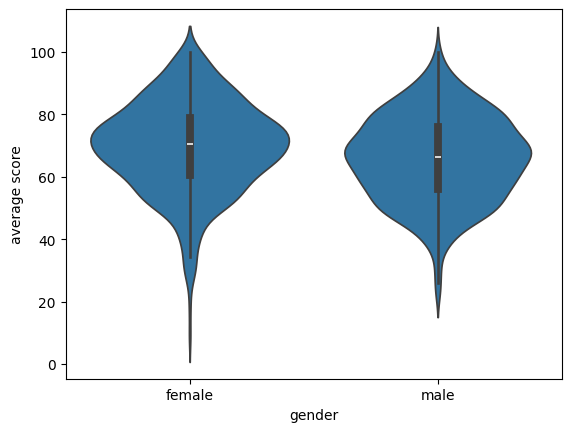

In [ ]:
# @title
sns.violinplot(data=df_clean, x="gender", y="average score")

<Axes: xlabel='test preparation course', ylabel='average score'>

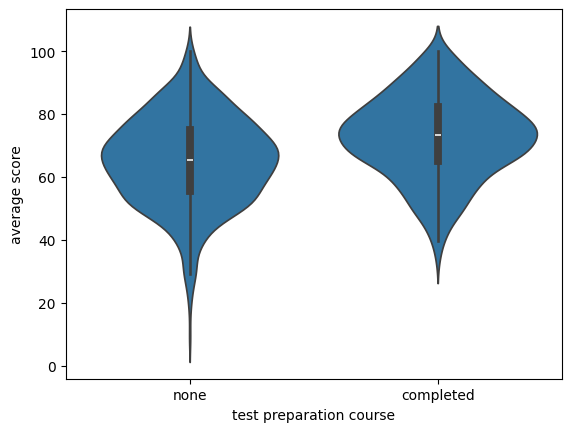

In [ ]:
# @title
sns.violinplot(data=df_clean,x="test preparation course",y="average score")

<Axes: xlabel='race/ethnicity', ylabel='average score'>

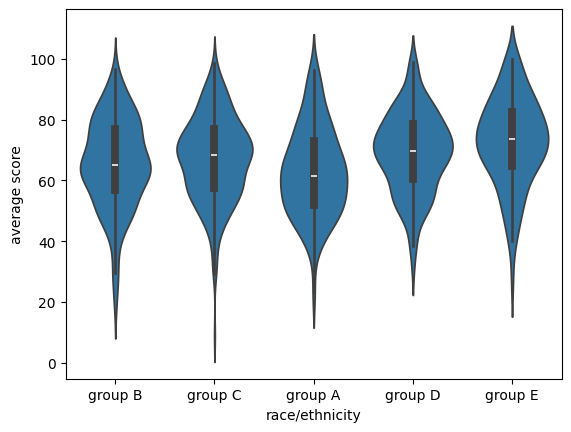

In [ ]:
# @title
sns.violinplot(data=df_clean,x="race/ethnicity",y="average score")

<Axes: xlabel='lunch', ylabel='average score'>

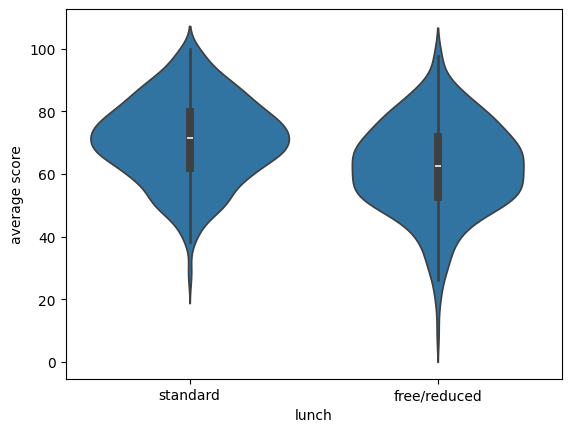

In [ ]:
# @title
sns.violinplot(data=df_clean,x="lunch",y="average score")

<Axes: >

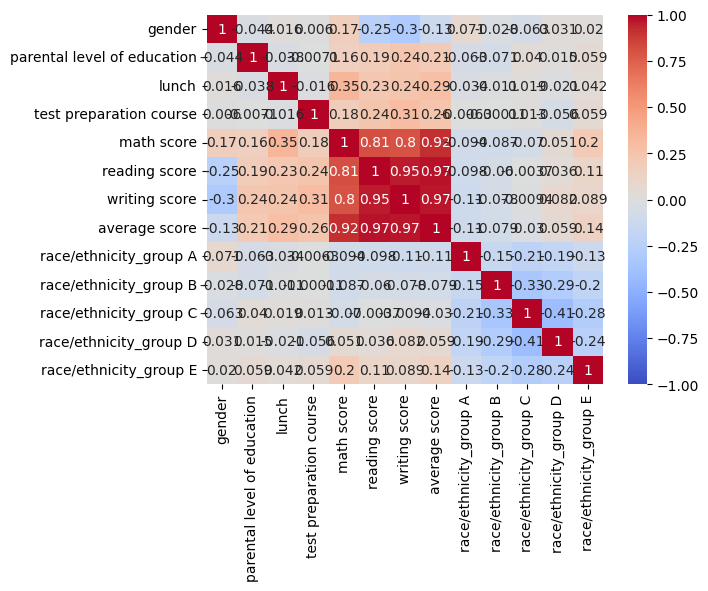

In [ ]:
# @title
corr = df_encoded.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin = -1 , vmax=1)

---
# Assignment #2

| Part | Content | Responsible | Rubric |
|---|---|---|---|
| A | Brief, design process & shared colours/style | Maryam Ajabnoor (Leader) | Design Process |
| B | 1D distributions | Manar Bawadood | EDA – 2 |
| C | Bivariate analysis & correlations | Somayah Alkhateeb | EDA – 2 |
| D | Encoding fix, hypotheses, assumptions & statistical model | Salma Shelbabi | EDA – 1 + Modelling – 1 |
| E | Draft → improved visualizations | Maryam Ajabnoor | Visualization – 2 |
| F | Advanced visualization & final dashboard | Aljawharah Alsaadi | Visualization – 2 |
| G | Conclusions & final review | Maryam Ajabnoor (Leader) | — |


# Part A — Brief & Design Process
**Responsible:** Maryam Ajabnoor  


## Brief

**Why**: The goal is to explore the dataset to find which background factors are associated with students' scores, and to communicate the key findings in a clear and readable way.

**Who**: Educational organizations, such as school administrators and teachers, who want to understand the relationship between students' scores and their background factors.

**What**: The cleaned Students Performance dataset (1,000 students), focusing on the three scores (math, reading, writing) and the categorical factors (gender, race/ethnicity, parental level of education, lunch, test preparation course).

**How**: A figure is considered successful when the reader can understand its main finding from the title and the plot alone, read the values correctly, and compare groups fairly.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import plotly.express as px

#Shared visual style (used by every plot in Assignment #2)

# 1) One look + one size for all plots (applied automatically)
sns.set_theme(
    style="whitegrid", context="notebook",
    rc={"figure.figsize": (8, 4),
        "axes.titlesize": 14, "axes.labelsize": 12,
        "xtick.labelsize": 11, "ytick.labelsize": 11,
        "grid.alpha": 0.3}
)

# 2) Binary features: accent = favourable condition, grey = the other condition
ACCENT, NEUTRAL = "#0072B2", "#999999"
lunch_colours  = {"standard": ACCENT, "free/reduced": NEUTRAL}
tp_colours     = {"completed": ACCENT, "none": NEUTRAL}

# 3) Gender: its own pair, different from the accent/grey pair
gender_colours = {"female": "#CC79A7", "male": "#E69F00"}

# 4) Ordinal feature: sequential palette, dark -> light = low -> high education
edu_colors = dict(zip(edu_order, sns.color_palette("viridis", len(edu_order) + 1)[:len(edu_order)]))

# 5) Nominal feature: one neutral color
race_order   = sorted(df_clean["race/ethnicity"].unique())
race_colours = race_colours = {group: "#6E6E6E" for group in race_order}

# 6) Subjects: one fixed color per score
subject_colours = {"math score": "#009E73", "reading score": "#D55E00", "writing score": "#56B4E9"}

# 7) Correlation heatmaps: diverging palette centred at 0
corr_cmap = "vlag"

# 8) Plotly (dashboard): same look; use the dicts above with color_discrete_map=
px.defaults.template = "simple_white"


## Design Process (Kirk's stages)

**1. Brief**: Described above.

**2. Working with data**: The cleaned dataset from Assignment #1 was used. A readable text copy (`df_clean`) was kept for plotting, and a separate encoded copy (`df_encoded`) was used for correlations and statistics.

**3. Editorial thinking**: The analysis focuses on how the background factors relate to the three scores. Time-series and network views were not used because the dataset has no time stamps or links between entities. Derived columns such as `average score` were excluded from correlations to avoid misleading results.

**4. Representation**: Each chart type was chosen based on the question: histograms and boxplots for distributions, bar charts for comparing categories, scatterplots and a heatmap for relationships, and boxplots for comparing scores across groups.

**5. Interactivity**: Interactivity was used only in the final dashboard, where a dropdown lets the reader choose a factor and all related views update together.

**6. Annotation**: Every plot has a takeaway title, axis labels with units, and values shown directly on the plot where possible.

**7. Colour**: One colour scheme is shared across all plots. Blue marks the favourable condition and grey the other, parental education uses a sequential palette because it is ordinal, and correlations use a diverging palette centred at 0. All colours are colour-blind safe.

**8. Composition**: Related plots were grouped in subplots with shared axes for fair comparison, and the most important view was placed at the top-left of the dashboard.

# Part B — 1D Distributions
**Responsible:** Manar Bawadood  




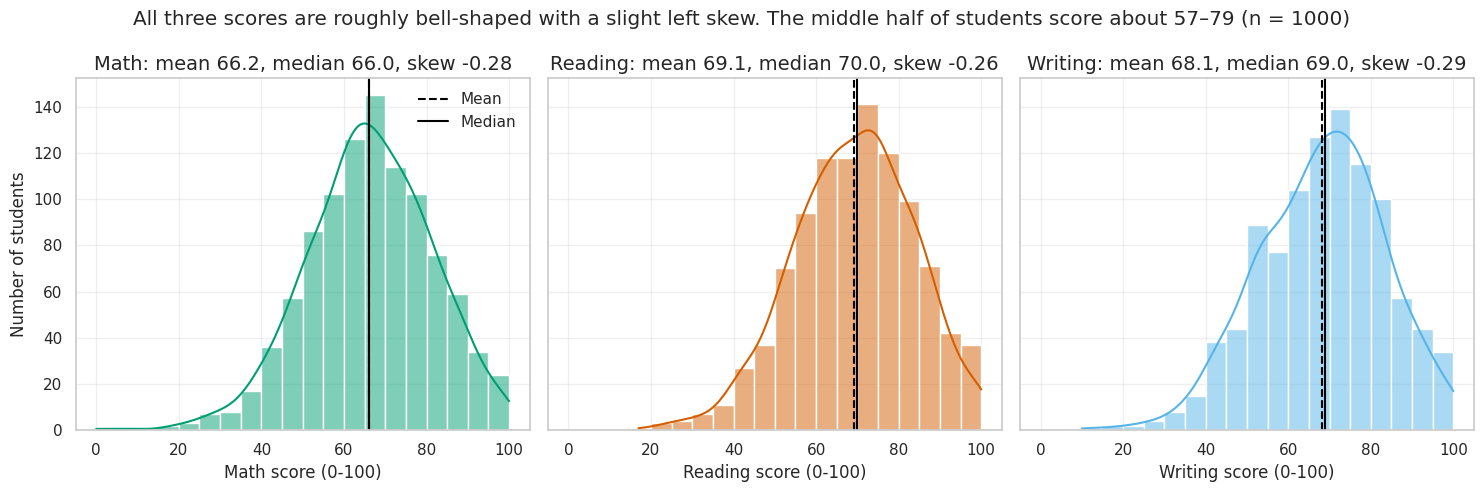

In [ ]:
fig, axs = plt.subplots(1, 3, sharey=True, sharex=True, tight_layout=True, figsize=(15, 5))

sns.histplot(data=df_clean, x='math score', binwidth=5, binrange=(0, 100), kde=True, ax=axs[0], color=subject_colours['math score'])
sns.histplot(data=df_clean, x='reading score', binwidth=5, binrange=(0, 100), kde=True, ax=axs[1], color=subject_colours['reading score'])
sns.histplot(data=df_clean, x='writing score', binwidth=5, binrange=(0, 100), kde=True, ax=axs[2], color=subject_colours['writing score'])

axs[0].set_ylabel('Number of students')
axs[0].set_xlabel('Math score (0-100)')
axs[1].set_xlabel('Reading score (0-100)')
axs[2].set_xlabel('Writing score (0-100)')

math_mean = df_clean['math score'].mean()
math_median = df_clean['math score'].median()
math_skew = df_clean['math score'].skew()
axs[0].axvline(math_mean, color='black', linestyle='--', label='Mean')
axs[0].axvline(math_median, color='black', linestyle='-', label='Median')
axs[0].set_title(f'Math: mean {math_mean:.1f}, median {math_median:.1f}, skew {math_skew:.2f}')
axs[0].legend(frameon=False)

reading_mean = df_clean['reading score'].mean()
reading_median = df_clean['reading score'].median()
reading_skew = df_clean['reading score'].skew()
axs[1].axvline(reading_mean, color='black', linestyle='--')
axs[1].axvline(reading_median, color='black', linestyle='-')
axs[1].set_title(f'Reading: mean {reading_mean:.1f}, median {reading_median:.1f}, skew {reading_skew:.2f}')

writing_mean = df_clean['writing score'].mean()
writing_median = df_clean['writing score'].median()
writing_skew = df_clean['writing score'].skew()
axs[2].axvline(writing_mean, color='black', linestyle='--')
axs[2].axvline(writing_median, color='black', linestyle='-')
axs[2].set_title(f'Writing: mean {writing_mean:.1f}, median {writing_median:.1f}, skew {writing_skew:.2f}')

fig.suptitle(f'All three scores are roughly bell-shaped with a slight left skew. The middle half of students score about 57–79 (n = {len(df_clean)})')
plt.show()


##Histograms: Interpretation

- All three scores form a single, roughly bell-shaped curve with one peak and no sign of a second group. Most students score in the middle of the range, and fewer score at the very low or very high ends.

- All three distributions lean slightly to the left, meaning the tail stretches toward the lower scores. In each subject the mean is a little below the median: Math 66.2 vs 66.0, reading 69.1 vs 70.0, and writing 68.1 vs 69.0. The skew values (-0.28, -0.26, -0.29) are all negative but within the -0.5 to 0.5 range, so the skew is mild, and the distributions are close to symmetric.

- The left tail comes from a small number of students with low scores, which pulls the mean slightly below the median in each subject.

So what? The three subjects have very similar distributions. Reading has the highest median (70), followed by writing (69), and math has the lowest (66).



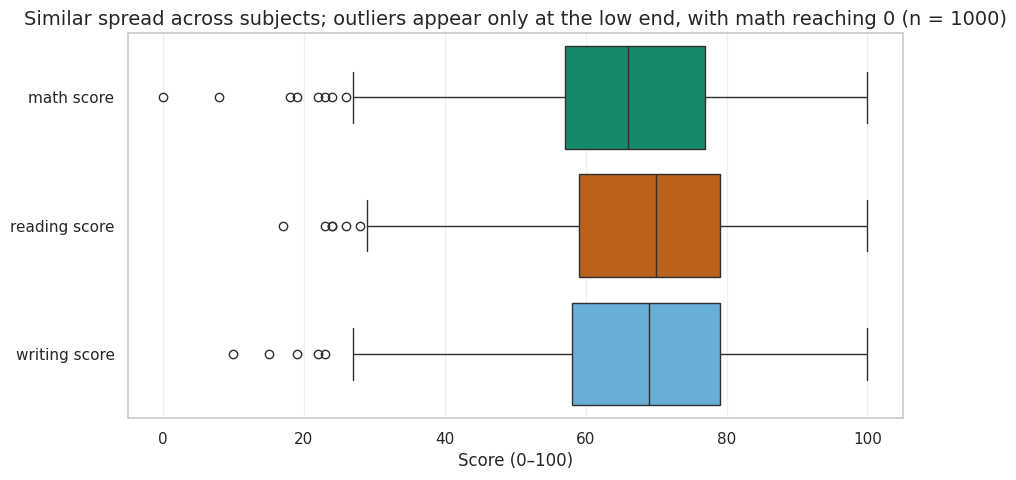

In [ ]:
scores_long = df_clean[score_cols].melt(var_name='subject', value_name='score')

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=scores_long, x='score', y='subject', hue='subject',
            palette=subject_colours, legend=False, ax=ax)

ax.set_xlabel('Score (0–100)')
ax.set_ylabel('')
ax.set_title(f'Similar spread across subjects; outliers appear only at the low end, with math reaching 0 (n = {len(df_clean)})')
plt.show()

##Boxplots: Interpretation

- In all three subjects the median sits inside the box, close to its middle, which matches the histograms.

- The boxes have similar widths across the three subjects, so the spread of the middle half of students is similar. The upper whiskers reach 100 in every subject.

- Outliers appear only at the low end in all three subjects, which agrees with the mild left skew in the histograms. Math reaches 0, the lowest value in the data.

So what? The three subjects behave in a similar way: most students score in the upper-middle range, there are no high-end outliers, and a small group of students scores far below the rest.

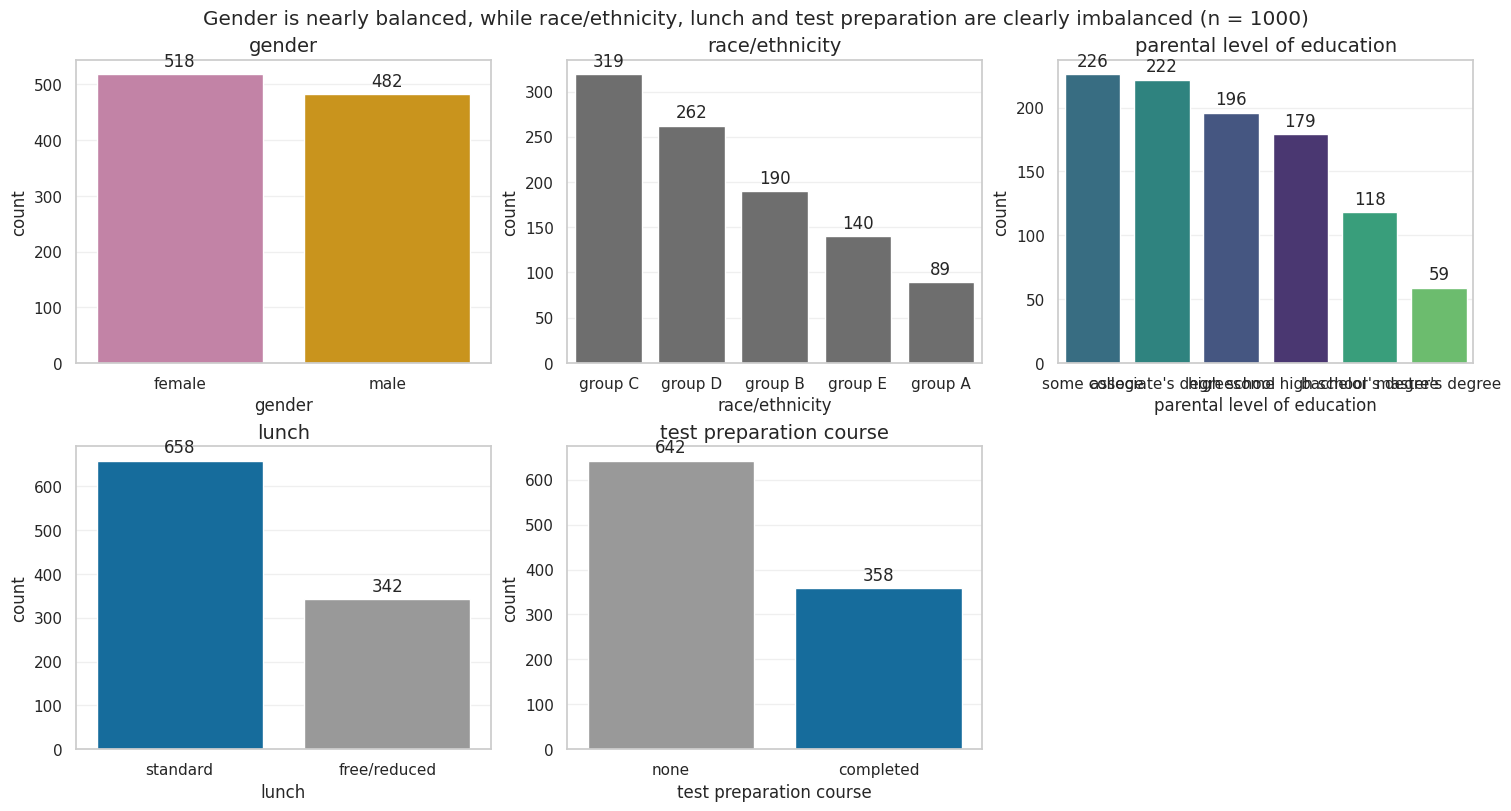

In [ ]:
fig, axs = plt.subplots(2,3, figsize=(15,8),layout='constrained')
axs[0,0].set_title('gender')
axs[0,1].set_title('race/ethnicity')
axs[0,2].set_title('parental level of education')
axs[1,0].set_title('lunch')
axs[1,1].set_title('test preparation course')
sns.countplot(data=df_clean, x='gender', hue='gender', legend=False, ax =axs[0,0],order = df_clean['gender'].value_counts().index, palette=gender_colours)
sns.countplot(data=df_clean, x='race/ethnicity', hue='race/ethnicity', legend=False, ax =axs[0,1],order = df_clean['race/ethnicity'].value_counts().index, palette=race_colours)
sns.countplot(data=df_clean, x='parental level of education', hue='parental level of education', legend=False, ax =axs[0,2],order = df_clean['parental level of education'].value_counts().index,  palette=edu_colors)
sns.countplot(data=df_clean, x='lunch', hue='lunch', legend=False, ax =axs[1,0],order = df_clean['lunch'].value_counts().index,  palette=lunch_colours)
sns.countplot(data=df_clean, x='test preparation course', hue='test preparation course', legend=False, ax =axs[1,1],order = df_clean['test preparation course'].value_counts().index,  palette=tp_colours)

def label_bars(ax):
    for bars in ax.containers:
        ax.bar_label(bars, padding=3)
label_bars(axs[0, 0]); label_bars(axs[0, 1]); label_bars(axs[0, 2])
label_bars(axs[1, 0]); label_bars(axs[1, 1])

axs[1, 2].axis('off')
fig.suptitle(f'Gender is nearly balanced, while race/ethnicity, lunch and test preparation are clearly imbalanced (n = {len(df_clean)})')
plt.show()

##Countplots: Interpretation

- Gender: The dataset is nearly balanced: 518 female and 482 male students, a difference of only 36. Neither group dominates, so gender comparisons later in the analysis will not be distorted by group size.

- Race/ethnicity: The groups are clearly unequal. Group C is the largest (319) and group A is the smallest (89), so group C has more than three times as many students as group A. Groups D (262), B (190) and E (140) fall in between. Any comparison across groups should keep these different sizes in mind, since results for group A rest on far fewer students.

- Parental level of education: The counts range from 226 down to 59, with the smallest category at 59 students. The largest categories are close to each other (226, 222, 196, 179), while the smallest ones are noticeably rarer (118 and 59). Therefore, most of the students who come from families in the middle of the education range, and the highest level has the fewest students.

- Lunch: Standard lunch is the larger group with 658 students, compared with 342 on free/reduced lunch. About two-thirds of students have standard lunch, so this feature is imbalanced.

- Test preparation course: Most students did not take the course: 642 have none and 358 completed it. This is also about a two-thirds to one-third split, similar to lunch.

So what? Gender is the only feature that is close to balanced. Race/ethnicity, lunch and test preparation are all imbalanced, so smaller groups (especially group A and the completed-course group) have less data behind them, and their averages are less reliable. This is worth keeping in mind in the bivariate analysis, where we compare scores across these groups.

# Part C — Bivariate Analysis
**Responsible:** Somayah Alkhateeb  




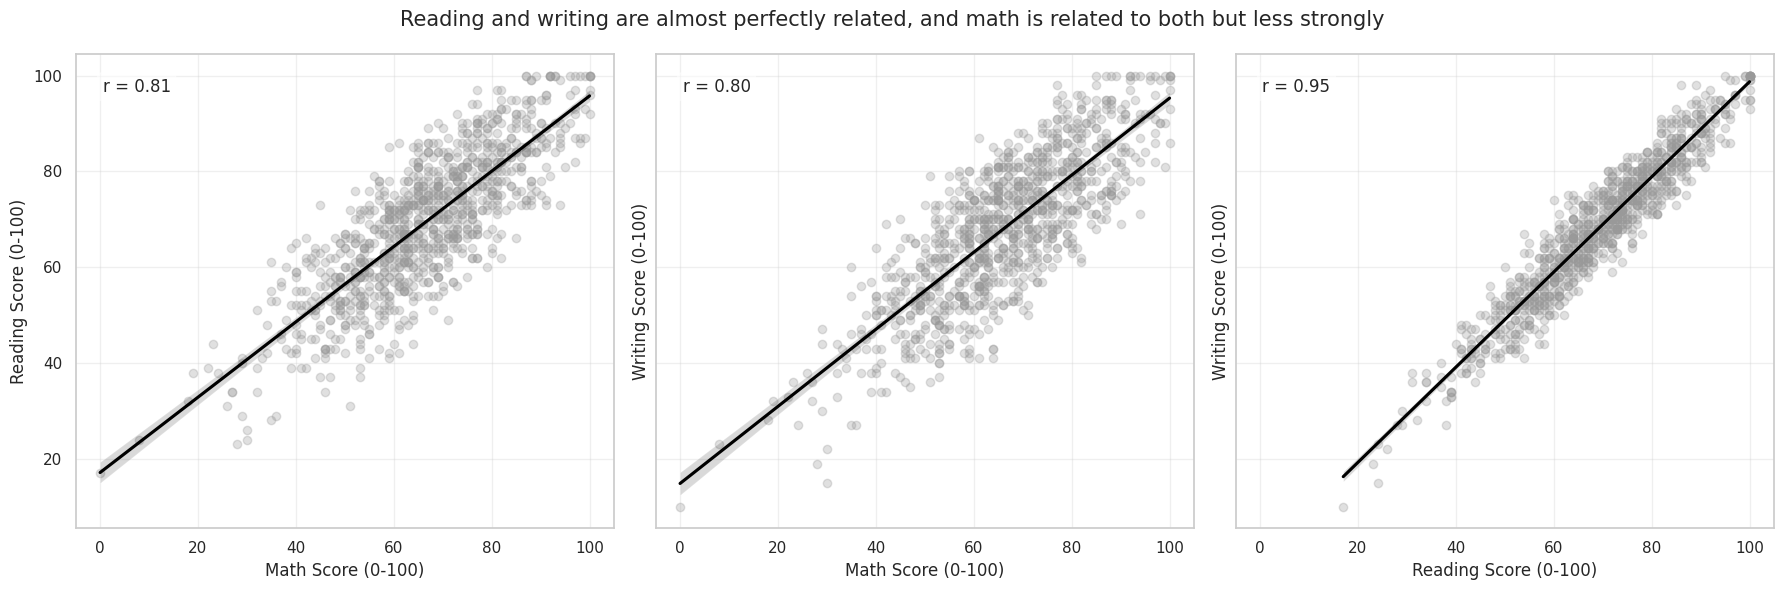

In [ ]:
# Create a figure with 3 subplots (1 row, 3 columns)
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True, sharex=True)

# Scatterplot 1 : Math vs Reading Scores
# ( alpha = 0.3 ) is used because scores are integers and points overlap.
sns.regplot(data=df_clean, x='math score', y='reading score',
            scatter_kws={'alpha':0.3, 'color':NEUTRAL}, line_kws={'color':'black'}, ax=axes[0])

# Compute Pearson correlation coefficient (r)
r1 = df_clean['math score'].corr(df_clean['reading score'])

# Display the computed 'r' inside the plot as text
axes[0].text(0.05, 0.95, f'r = {r1:.2f}', transform=axes[0].transAxes, fontsize=12,
             verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))
axes[0].set_xlabel("Math Score (0-100)")
axes[0].set_ylabel("Reading Score (0-100)")


# Scatterplot 2 : Math vs Writing Scores
# ( alpha = 0.3 ) is used because scores are integers and points overlap.
sns.regplot(data=df_clean, x='math score', y='writing score',
            scatter_kws={'alpha':0.3, 'color':NEUTRAL}, line_kws={'color':'black'}, ax=axes[1])

# Compute Pearson correlation coefficient (r)
r2 = df_clean['math score'].corr(df_clean['writing score'])

# Display the computed 'r' inside the plot as text
axes[1].text(0.05, 0.95, f'r = {r2:.2f}', transform=axes[1].transAxes, fontsize=12,
             verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))
axes[1].set_xlabel("Math Score (0-100)")
axes[1].set_ylabel("Writing Score (0-100)")


# Scatterplot 3 : Reading vs Writing Scores
# ( alpha = 0.3 ) is used because scores are integers and points overlap.
sns.regplot(data=df_clean, x='reading score', y='writing score',
            scatter_kws={'alpha':0.3, 'color':NEUTRAL}, line_kws={'color':'black'}, ax=axes[2])

# Compute Pearson correlation coefficient (r)
r3 = df_clean['reading score'].corr(df_clean['writing score'])

# Display the computed 'r' inside the plot as text
axes[2].text(0.05, 0.95, f'r = {r3:.2f}', transform=axes[2].transAxes, fontsize=12,
             verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))
axes[2].set_xlabel("Reading Score (0-100)")
axes[2].set_ylabel("Writing Score (0-100)")

fig.suptitle("Reading and writing are almost perfectly related, and math is related to both but less strongly", fontsize=15)
plt.tight_layout()
plt.show()

## Scatterplot Interpretation
These scatterplots with regression lines illustrate the bivariate relationships between the three main subjects. A transparency parameter ( alpha = 0.3 ) was applied to handle the overlapping of integer scores. The visualizations indicate that all scores are positively associated with one another. The association between Reading and Writing scores is the strongest, as shown by the steep regression line and the highest correlation coefficient ( r = 0.95 ).

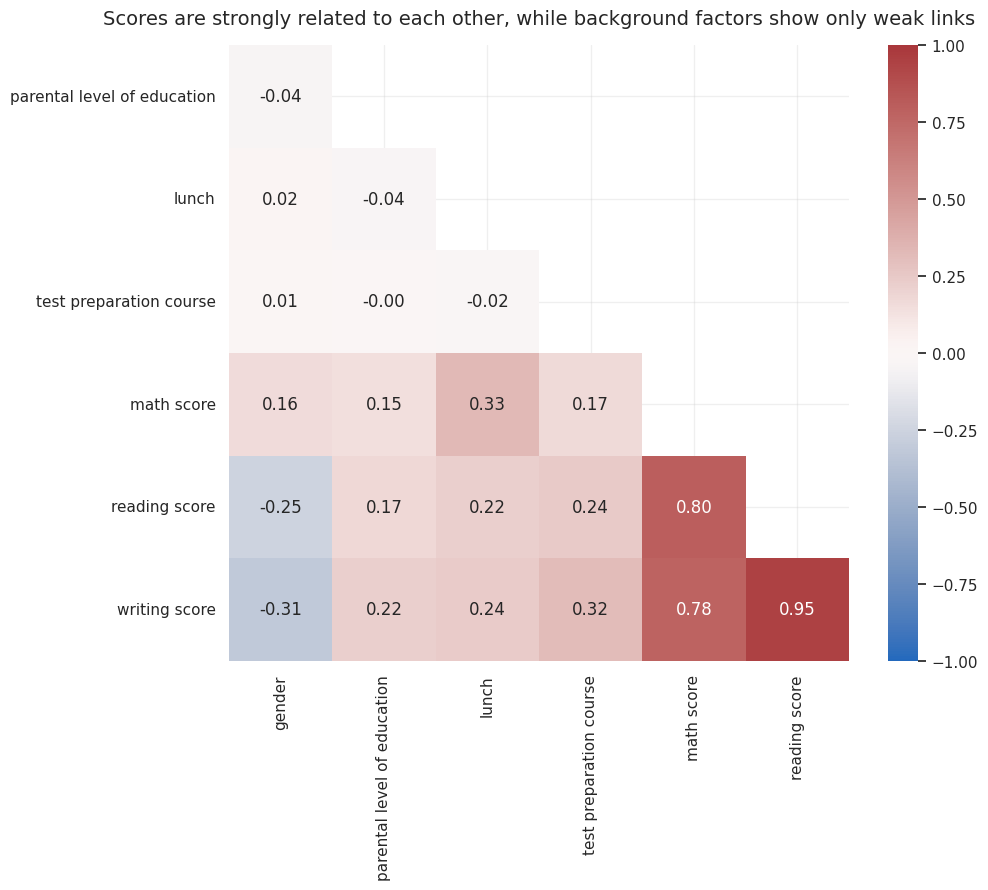

In [ ]:
# Calculate the correlation matrix for all numeric columns in the encoded dataframe
corr_matrix_all = df_encoded.drop(columns=["average score"] + [c for c in df_encoded.columns if c.startswith('race/ethnicity_')]).corr(method='spearman')

# Create a mask to hide the upper triangle
mask_all = np.triu(np.ones_like(corr_matrix_all, dtype=bool))

# Set a larger figure size to accommodate all variables
fig, ax = plt.subplots(figsize=(10, 8))

# Plot the comprehensive heatmap
sns.heatmap(corr_matrix_all.iloc[1:, :-1], mask=mask_all[1:, :-1], annot=True, fmt=".2f", cmap=corr_cmap,
            vmin=-1, vmax=1, center=0, ax=ax, )

# Add the title
ax.set_title('Scores are strongly related to each other, while background factors show only weak links', pad=15)
plt.show()

## Heatmap Interpretation
This comprehensive correlation heatmap visualizes the statistical relationships across all numerical and encoded categorical variables in the dataset. A mask was applied to hide the redundant upper triangle, and a diverging color map centered at zero was used to highlight positive and negative correlations.
Looking at the relationships between scores and other factors, we observe that taking a test preparation course is positively associated with higher scores ( correlation ~0.24-0.35 ). and having a standard lunch is also positively associated with higher scores, particularly in math. But the strongest associations remain among the scores themselves.

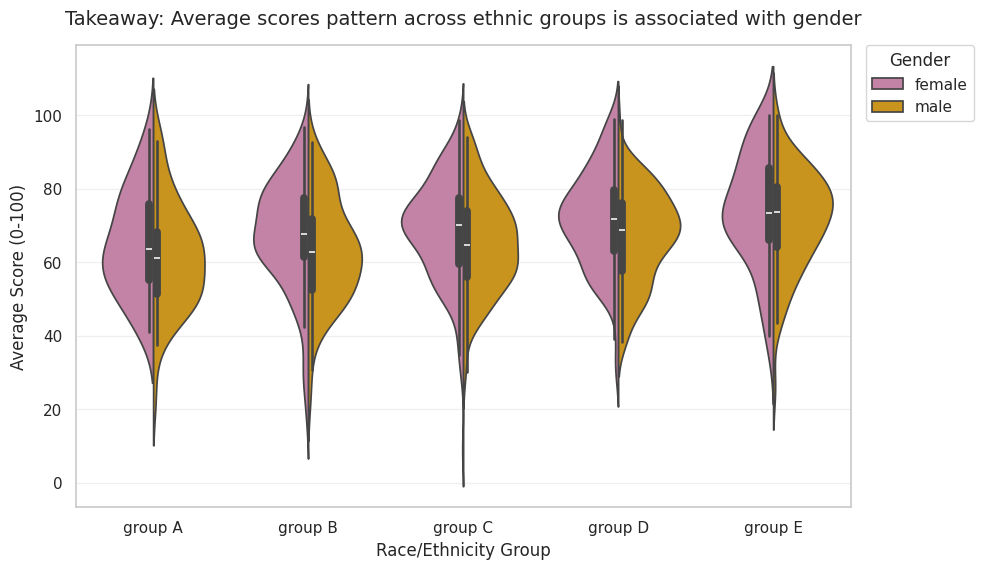

In [ ]:
# Define the order for the ethnic groups
group_order = ['group A', 'group B', 'group C', 'group D', 'group E']

# Set up the figure size for clear visibility
fig, ax = plt.subplots(figsize=(10, 6))

# Create a split violin plot to examine average score distributions across groups.
# 'hue' is set to gender to check for patterns inside subgroups
# 'palette' uses the shared gender colours from Part A
sns.violinplot(data=df_clean, x='race/ethnicity', y='average score',
               hue='gender', split=True, palette=gender_colours,
               order=group_order, ax=ax)

# Add titles
ax.set_title("Takeaway: Average scores pattern across ethnic groups is associated with gender", pad=15)
ax.set_xlabel("Race/Ethnicity Group")
ax.set_ylabel("Average Score (0-100)")

plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title='Gender', borderaxespad=0)

# Display the final plot
plt.show()

## Violinplot Interpretation

This split violin plot examines the distribution of the average score across different racial/ethnic groups, ordered from Group A to Group E. By introducing gender as a hue, we inspect patterns within subgroups. The visual indicates that across all ethnic groups, females tend to have a slightly higher median average score compared to males, showing that the score distribution pattern across groups is associated with gender.

# Part D — Hypotheses & Statistical Modelling
**Responsible:** Selma Chelbabi  


### **H1: The feature (test preparation course) is associated with the average score in a positive way.**
-  Ho: Test preparation course is not associated with the average score in a positive way.
-  H1: Test preparation course is associated with the average score in a positive way

Since the the independant variable (Test preparation course) is a categorical variable
consisting of 2 groups and the dependant variable (average score) is numerival: the hypothesis testing method that will be used is T-test.

-  There are 4 requirements for T-test:
1)  Independance of the points in the dependant variable.
2)  The independant variable points should follow a normal distribution.
3)  The variance within each group in the independant variable should be approximatly equal.
4)  Absence of outliers

In [ ]:
pip install pingouin

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 31.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 71.9 MB/s  0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.10.0
    Uninstalling matplotlib-3.10.0:
      Successfully uninstalled matplotlib-3.10.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [pingouin]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.


In [ ]:
import pingouin as pg
import scipy.stats as stats

normality_test=pg.normality(df_clean, dv='average score', group='test preparation course')
print('Normality: ')
print(normality_test)
Levene_test=pg.homoscedasticity(df_clean, dv='average score', group='test preparation course', method='levene', alpha=0.05)
print()
print(Levene_test)

Normality: 
                                W      pval  normal
test preparation course                            
none                     0.993577  0.007731   False
completed                0.990736  0.023770   False

               W      pval  equal_var
levene  2.737185  0.098352       True


/tmp/ipykernel_540/4001906264.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f'None (n = {n_none})', f'Completed (n = {n_done})'])


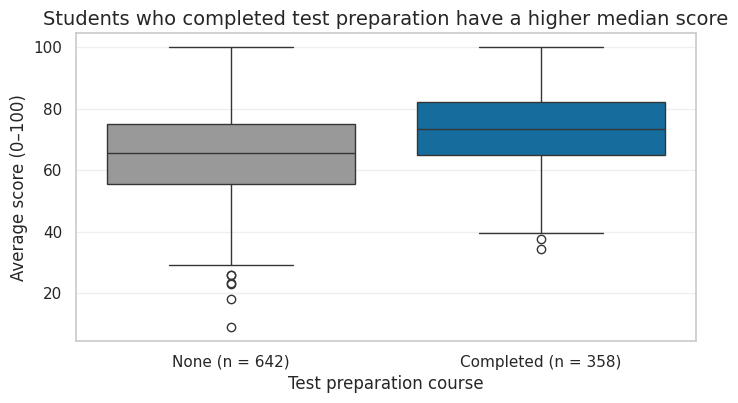

In [ ]:
n_none = (df_clean['test preparation course'] == 'none').sum()
n_done = (df_clean['test preparation course'] == 'completed').sum()

ax = sns.boxplot(data=df_clean, x='test preparation course', y='average score',
                 hue='test preparation course', palette=tp_colours,
                 order=['none', 'completed'], legend=False)
ax.set_xticklabels([f'None (n = {n_none})', f'Completed (n = {n_done})'])
ax.set_xlabel('Test preparation course')
ax.set_ylabel('Average score (0–100)')
ax.set_title('Students who completed test preparation have a higher median score')
plt.show()

The outcome (average score) is numeric and the two groups (none, completed) are independent, so an independent t-test is appropriate. The Shapiro–Wilk test showed a slight deviation from normality in both groups, and the boxplots show a slight skew with few outliers; with large groups (642 and 358 students), the t-test is robust to this deviation. Levene's test showed equal variances (p = 0.098), so the standard t-test with equal variances was used.



In [ ]:


A=df_clean[df_clean['test preparation course']=='completed']['average score']
B=df_clean[df_clean['test preparation course']=='none']['average score']

t_val,p_val=stats.ttest_ind(A,B)
alpha=0.05
dff_t=len(A)+len(B)-2
critical_t=stats.t.ppf(1-alpha/2,dff_t)

print(f'T value: {t_val.round(4)}')
print(f'P value: {p_val.round(4)}')
print(f'Critical t-value: {critical_t.round(4)}')

print('T-test Result:')
if np.abs(t_val) >critical_t:
    print('Significant difference found.')
else:
    print('No significant difference.')

print('P-test Result:')
if p_val < alpha:
    print('Reject H0. Significant difference found.')
else:
   print('Fail to reject H0. No strong evidence of difference.')

T value: 8.413
P value: 0.0
Critical t-value: 1.9623
T-test Result:
Significant difference found.
P-test Result:
Reject H0. Significant difference found.


-  T-value (8.413) is much greater than the critical t-value (1.9623), so we reject the null hypothesis.
-  The P-value (0.0) is much smaller than 0.05, also indicating a significant result.

### **H2: The Education level of parents is associated with student's average score.**
-  Ho: The Education level of parents is not associated with the student's average score
-  H1: The Educational level of parents is associated with the student's average score.

Since the the independant variable (parental level of education) is a categorical variable
consisting of 3+groups and the dependant variable (average score) is numerical: the hypothesis testing method that will be used is ANOVA.

-  There are 3 requirements for ANOVA:
1)  Independance of the points in the independant variable.
2)  The independant variable points should follow a normal distribution.
3)  The variance within each group in the independant variable should be approximatly equal.




In [ ]:

normality_test=pg.normality(df_clean, dv='average score', group='parental level of education')
print('Normality: ')
print(normality_test)
Levene_test=pg.homoscedasticity(df_clean, dv='average score', group='parental level of education', method='levene', alpha=0.05)
print()
print(Levene_test)

Normality: 
                                    W      pval  normal
parental level of education                            
bachelor's degree            0.987325  0.339909    True
some college                 0.988000  0.055325    True
master's degree              0.975106  0.266858    True
associate's degree           0.989605  0.110175    True
high school                  0.988332  0.108671    True
some high school             0.978979  0.008317   False

               W      pval  equal_var
levene  0.522304  0.759537       True


The normality test results show that the groups have a normal distribution except for (some high school); the levene's test results show that there's equality in variance.

                        Source  ddof1  ddof2        F  p_unc     np2
0  parental level of education      5    994  10.8933    0.0  0.0519


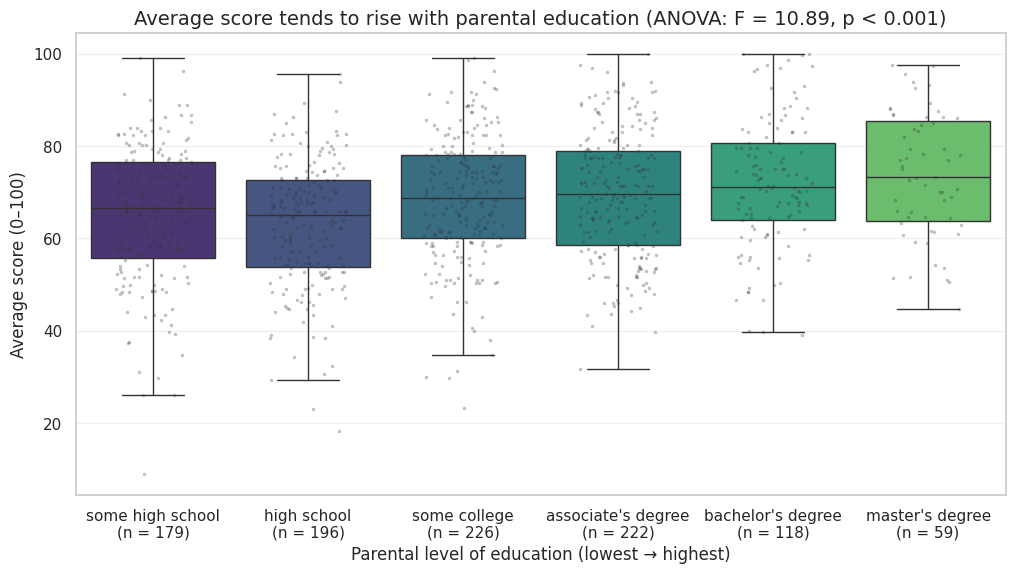

In [ ]:
Anova_test = pg.anova(df_clean, dv='average score', between='parental level of education').round(4)
print(Anova_test)

f_val = Anova_test.loc[0, "F"]
p_val = Anova_test.loc[0, "p_unc"]
p_text = "p < 0.001" if p_val < 0.001 else f"p = {p_val:.3f}"

group_n = df_clean['parental level of education'].value_counts()

fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=df_clean, x="parental level of education", y="average score",
            hue="parental level of education", order=edu_order, palette=edu_colors,
            legend=False, showfliers=False, ax=ax)
sns.stripplot(data=df_clean, x="parental level of education", y="average score",
              order=edu_order, color="#333333", size=2.5, alpha=0.3, jitter=0.25, ax=ax)

ax.set_xticks(range(len(edu_order)))
ax.set_xticklabels([f"{level}\n(n = {group_n[level]})" for level in edu_order])
ax.set_xlabel("Parental level of education (lowest → highest)")
ax.set_ylabel("Average score (0–100)")
ax.set_title(f"Average score tends to rise with parental education (ANOVA: F = {f_val:.2f}, {p_text})")
plt.show()

-  The F_static score (10.89) represents the ratio of variance between the groups to variance in the groups.
-  The p_value named p_unc (0.0) is below the threshold 0.05 so the null hypothesis is rejected, which means that The Educational level of parents is associated with the student's average score.


### **H3: There is a relationship between the race/ethnicity of the student with their average score.**
-  Ho: There is no relationship between the ethnicity/race of the student and their average score.
-  H1: There is actually a relationship between the ethnicity/race of the student and their average score.

Since the the independant variable (race/ethnicity) is a categorical variable consisting of 3+groups and the dependant variable (average score) is numerival: the hypothesis testing method that will be used is ANOVA.

-  There are 3 requirements for ANOVA:
1)  Independance of the points in the independant variable.
2)  The independant variable points should follow a normal distribution.
3)  The variance within each group in the independant variable should be approximatly equal.


In [ ]:
# ANOVA'S first and second requirement are met in this case , we will check the variance using levene's test.
import pingouin as pg

normality_test=pg.normality(df_clean, dv='average score', group='race/ethnicity')
print('Normality: ')
print(normality_test)
Levene_test=pg.homoscedasticity(df_clean, dv='average score', group='race/ethnicity', method='levene', alpha=0.05)
print()
print(Levene_test)


Normality: 
                       W      pval  normal
race/ethnicity                            
group B         0.982716  0.019162   False
group C         0.989087  0.017234   False
group A         0.986745  0.505870    True
group D         0.992348  0.194724    True
group E         0.983038  0.080389    True

               W      pval  equal_var
levene  0.595366  0.666062       True


The normality test results show that the groups have a normal distribution except for (group B and group C); the levene's test results show that there's equality in variance.

           Source  ddof1  ddof2       F  p_unc     np2
0  race/ethnicity      4    995  9.1596    0.0  0.0355


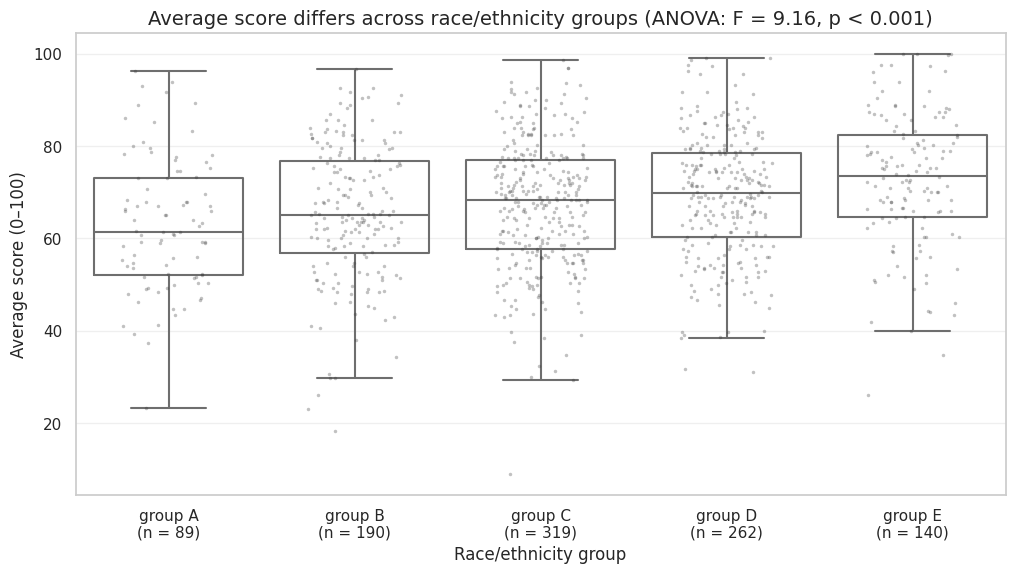

In [ ]:
Anova_test = pg.anova(df_clean, dv='average score', between='race/ethnicity').round(4)
print(Anova_test)

f_val = Anova_test.loc[0, "F"]
p_val = Anova_test.loc[0, "p_unc"]
p_text = "p < 0.001" if p_val < 0.001 else f"p = {p_val:.3f}"

group_n = df_clean['race/ethnicity'].value_counts()

fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=df_clean, x='race/ethnicity', y='average score',
            hue='race/ethnicity', order=race_order, palette=race_colours,
            legend=False, showfliers=False, fill=False, linewidth=1.5, ax=ax)
sns.stripplot(data=df_clean, x='race/ethnicity', y='average score',
              order=race_order, color="#333333", size=2.5, alpha=0.3, jitter=0.25, ax=ax)

ax.set_xticks(range(len(race_order)))
ax.set_xticklabels([f"{group}\n(n = {group_n[group]})" for group in race_order])
ax.set_xlabel("Race/ethnicity group")
ax.set_ylabel("Average score (0–100)")

ax.set_title(f"Average score differs across race/ethnicity groups (ANOVA: F = {f_val:.2f}, {p_text})")
plt.show()

-   The F_static score (9.159) represents the ratio of variance between the groups to variance in the groups.
-   The p_value named p_unc (0.0) is below the threshold 0.05 so the null hypothesis is rejected, which means that there is actually a relationship between the ethnicity/race of the student and their average score.

# Part E — Draft → Improved Visualizations
**Responsible:** Maryam Ajabnoor



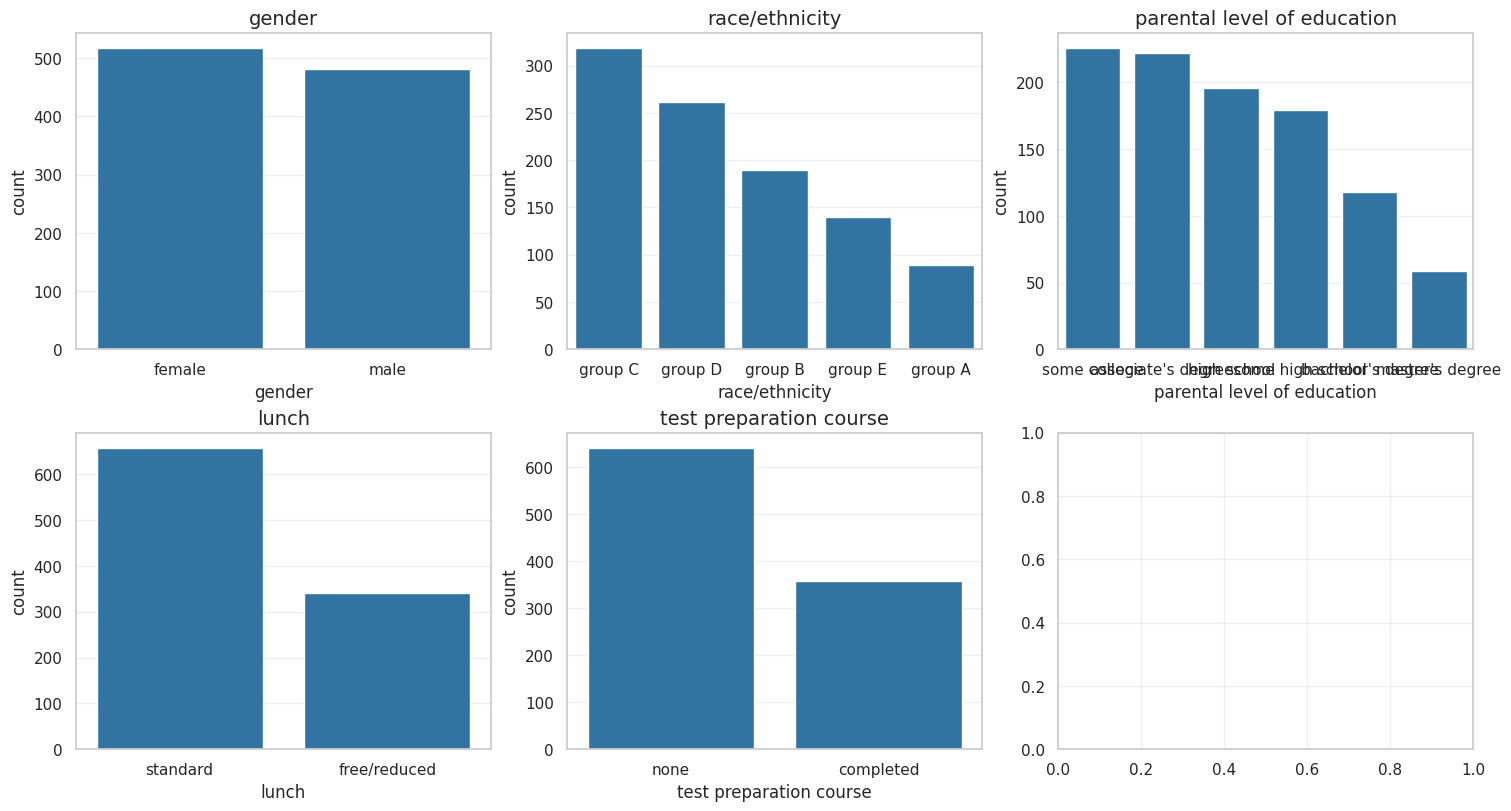

In [ ]:
fig, axs = plt.subplots(2,3, figsize=(15,8),layout='constrained')
axs[0,0].set_title('gender')
axs[0,1].set_title('race/ethnicity')
axs[0,2].set_title('parental level of education')
axs[1,0].set_title('lunch')
axs[1,1].set_title('test preparation course')
sns.countplot(data=df_clean, x='gender', ax =axs[0,0],order = df_clean['gender'].value_counts().index, color='#1f77b4')
sns.countplot(data=df_clean, x='race/ethnicity', ax =axs[0,1],order = df_clean['race/ethnicity'].value_counts().index, color='#1f77b4')
sns.countplot(data=df_clean, x='parental level of education', ax =axs[0,2],order = df_clean['parental level of education'].value_counts().index, color='#1f77b4')
sns.countplot(data=df_clean, x='lunch', ax =axs[1,0],order = df_clean['lunch'].value_counts().index, color='#1f77b4')
sns.countplot(data=df_clean, x='test preparation course', ax =axs[1,1],order = df_clean['test preparation course'].value_counts().index, color='#1f77b4')
plt.show()

## Draft 1 Problems
The problems with this draft are:
* No color assignment for different classes.
* Titles don't explain the figures.
* The real values for each bar are not clear.
* There is a plain chart that can be discarded.
* The class names (parent level of education) are interleaved and hard to read.

## Improvement: Draft 1 (countplot)


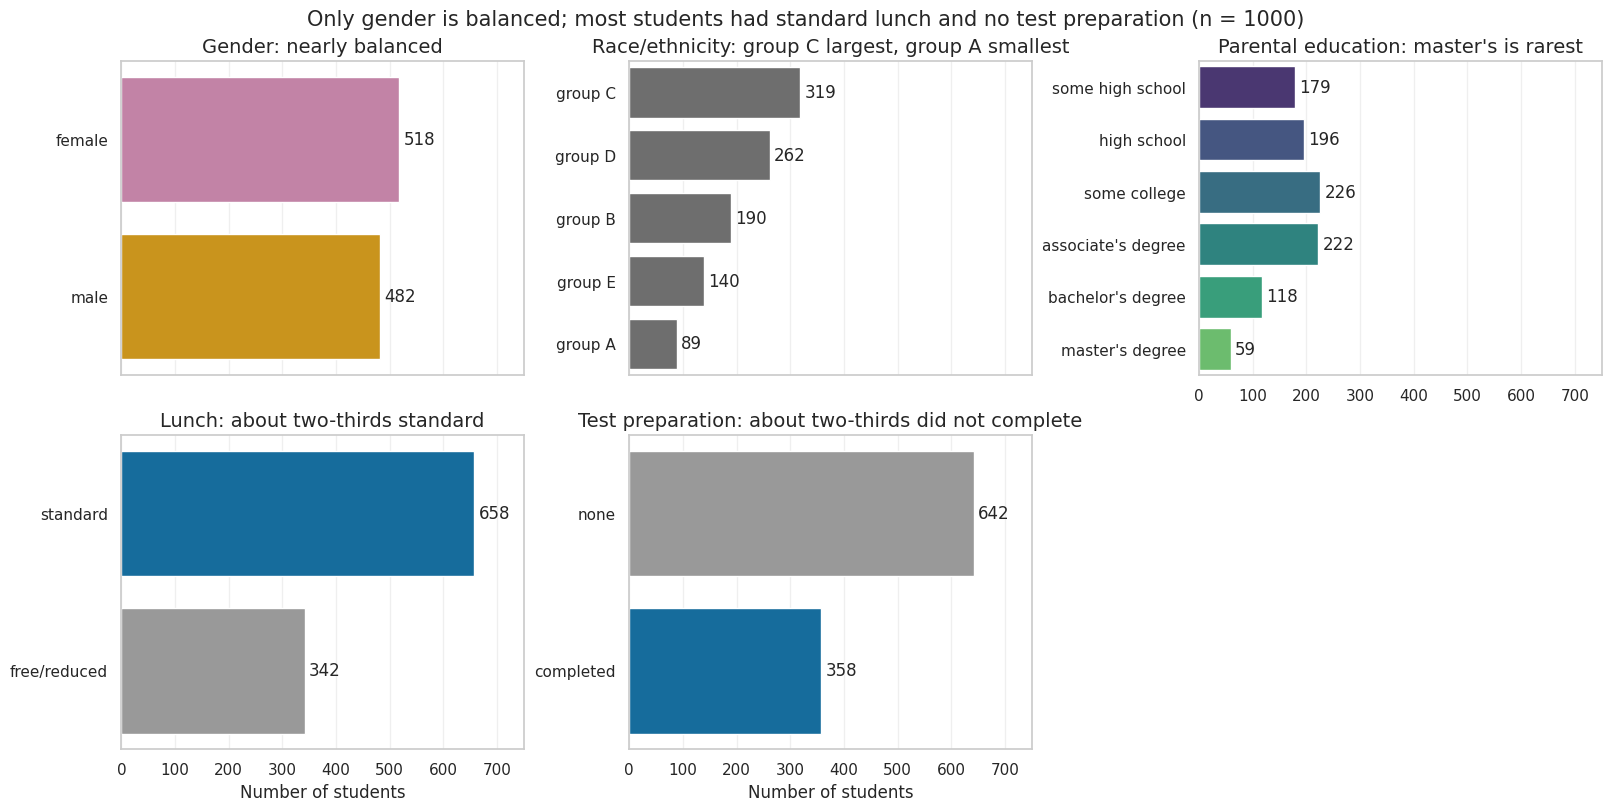

In [ ]:
def label_bars(ax):
    for bars in ax.containers:
        ax.bar_label(bars, padding=3)

fig, axs = plt.subplots(2, 3, figsize=(16, 8), sharex=True, layout='constrained')

sns.countplot(data=df_clean, y='gender', hue='gender', legend=False,
              order=df_clean['gender'].value_counts().index, palette=gender_colours, ax=axs[0, 0])
sns.countplot(data=df_clean, y='race/ethnicity', hue='race/ethnicity', legend=False,
              order=df_clean['race/ethnicity'].value_counts().index, palette=race_colours, ax=axs[0, 1])
sns.countplot(data=df_clean, y='parental level of education', hue='parental level of education', legend=False,
              order=edu_order, palette=edu_colors, ax=axs[0, 2])
sns.countplot(data=df_clean, y='lunch', hue='lunch', legend=False,
              order=df_clean['lunch'].value_counts().index, palette=lunch_colours, ax=axs[1, 0])
sns.countplot(data=df_clean, y='test preparation course', hue='test preparation course', legend=False,
              order=df_clean['test preparation course'].value_counts().index, palette=tp_colours, ax=axs[1, 1])

axs[0, 0].set_title('Gender: nearly balanced')
axs[0, 1].set_title('Race/ethnicity: group C largest, group A smallest')
axs[0, 2].set_title("Parental education: master's is rarest")
axs[1, 0].set_title('Lunch: about two-thirds standard')
axs[1, 1].set_title('Test preparation: about two-thirds did not complete')

label_bars(axs[0, 0]); label_bars(axs[0, 1]); label_bars(axs[0, 2])
label_bars(axs[1, 0]); label_bars(axs[1, 1])

axs[0, 0].set_xlim(0, 750)
axs[1, 0].set_xlabel('Number of students'); axs[1, 1].set_xlabel('Number of students')
axs[0, 2].tick_params(labelbottom=True); axs[0, 2].set_xlabel('Number of students')
axs[0, 0].set_ylabel(''); axs[0, 1].set_ylabel(''); axs[0, 2].set_ylabel('')
axs[1, 0].set_ylabel(''); axs[1, 1].set_ylabel('')
axs[1, 2].axis('off')

fig.suptitle(f'Only gender is balanced; most students had standard lunch and no test preparation (n = {len(df_clean)})', fontsize=15)
plt.show()


- The value was added at the end of each bar so the exact count can be read without estimating it from the axis.
- The bars were made horizontal because the long education labels were overlapping.
- Parental education was ordered from the lowest to the highest level because it is an ordinal variable, and sorting by count hid its natural order.
- The shared colours from Part A were used so each colour keeps the same meaning across all plots and stays colour-blind safe.
- The variable names were replaced with takeaway titles so each panel states its main finding.
- The axis was renamed to "Number of students" because the default "count" was not clear.
- A shared x-axis was used so the counts can be compared fairly between panels.
- The empty sixth panel was hidden to reduce clutter.

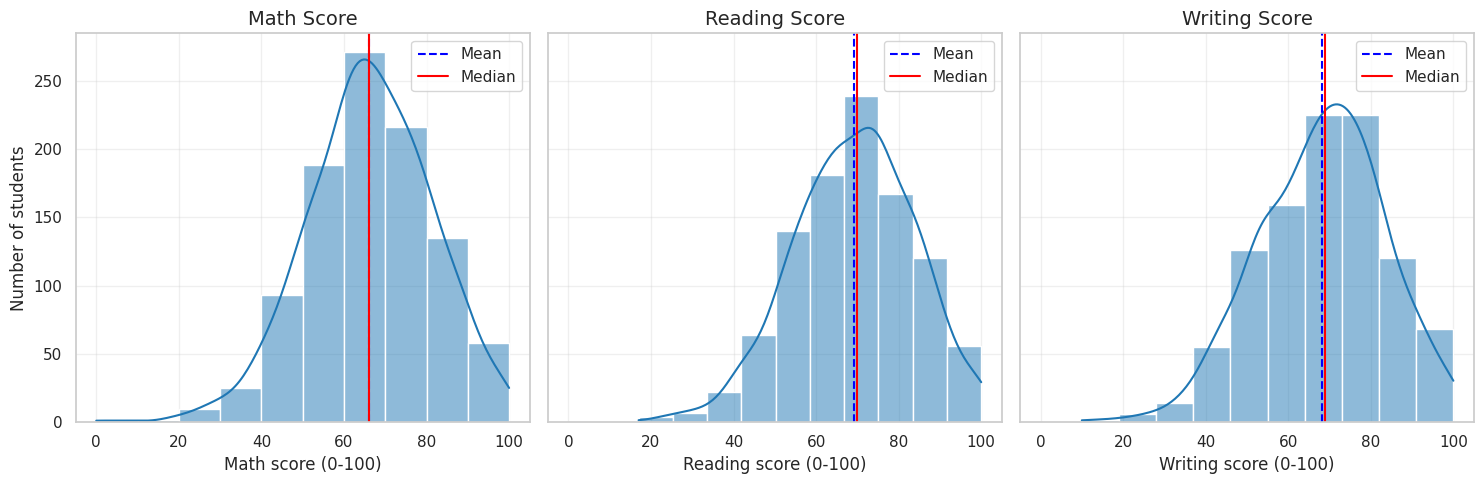

In [ ]:
n_bins = 10

fig, axs = plt.subplots(1, 3, sharey=True,sharex=True, tight_layout=True, figsize=(15, 5))

axs[0].set_ylabel('Number of students')
axs[0].set_title('Math Score')
axs[1].set_title('Reading Score')
axs[2].set_title('Writing Score')

sns.histplot(data=df_clean, x='math score', bins=n_bins, kde=True, ax=axs[0], color='#1f77b4')
sns.histplot(data=df_clean, x='reading score', bins=n_bins, kde=True, ax=axs[1], color='#1f77b4')
sns.histplot(data=df_clean, x='writing score', bins=n_bins, kde=True, ax=axs[2], color='#1f77b4')

axs[0].set_xlabel('Math score (0-100)')
axs[1].set_xlabel('Reading score (0-100)')
axs[2].set_xlabel('Writing score (0-100)')

mathmen=df_clean['math score'].mean()
mathmed=df_clean['math score'].median()
axs[0].axvline(mathmen, color='blue',label='Mean',linestyle='dashed')
axs[0].axvline(mathmed, color='red',label='Median')
axs[0].legend()

readingmen=df_clean['reading score'].mean()
readingmed=df_clean['reading score'].median()
axs[1].axvline(readingmen, color='blue',label='Mean', linestyle='dashed')
axs[1].axvline(readingmed, color='red',label='Median')
axs[1].legend()

writingmen=df_clean['writing score'].mean()
writingmed=df_clean['writing score'].median()
axs[2].axvline(writingmen, color='blue',label='Mean',linestyle='dashed')
axs[2].axvline(writingmed, color='red',label='Median')
axs[2].legend()

plt.show()

## Draft 2 Problems
- `bins=10` was calculated from each subject's own range, so the bin edges were different in each panel and the subjects could not be compared fairly.
- All subjects had the same default colour, which did not match the shared colours from Part A.
- The mean line was blue on top of blue bars, so it was hard to see, and the red/blue colours had no meaning.
- The legend was repeated in all three panels.
- The titles only named the subject and did not state a finding.
- The mean, median and skew values were not shown on the plot.

## Improvement: Draft 2


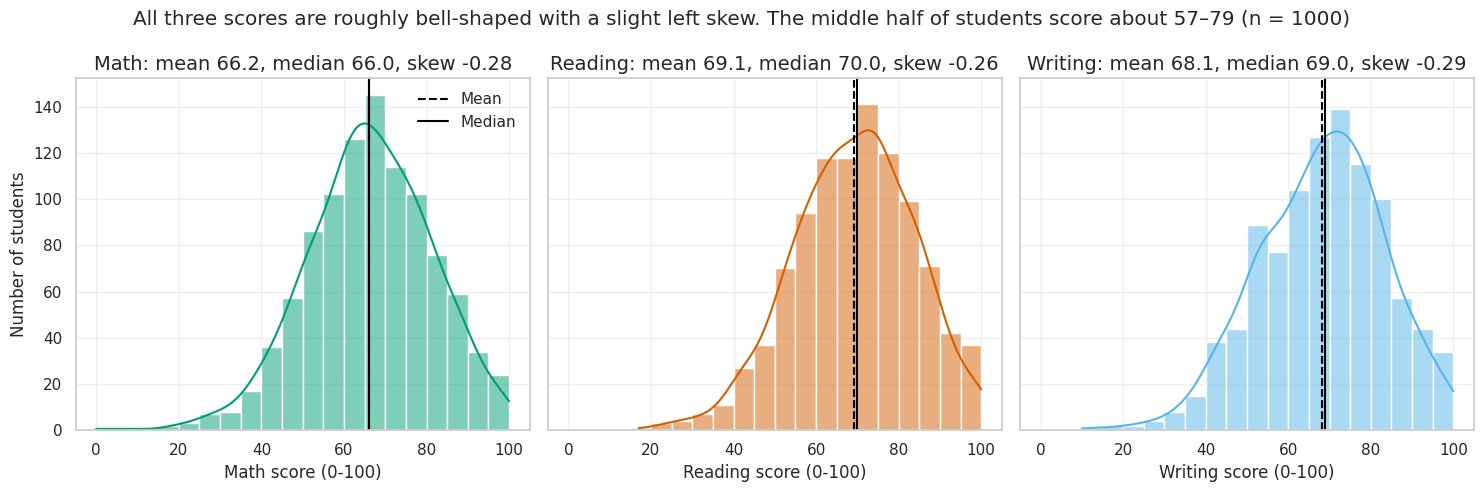




- A fixed bin width of 5 over the range 0–100 was used so all panels share the same bin edges and can be compared fairly.
- Each subject was given its own colour from Part A so the subject colours stay consistent across all plots.
- The mean and median lines were changed to black and distinguished by line style (dashed and solid) so they stand out from the bars without relying on colour.
- The legend was kept in the first panel only to reduce clutter.
- A takeaway title was added so the figure states its main finding.
- The mean, median and skew values were added to each panel title so the reader can read them directly.

> The improved version is the same figure shown in Part B. You can go back to see the code.

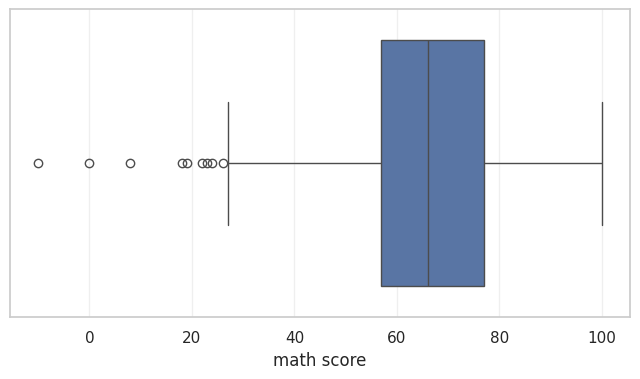

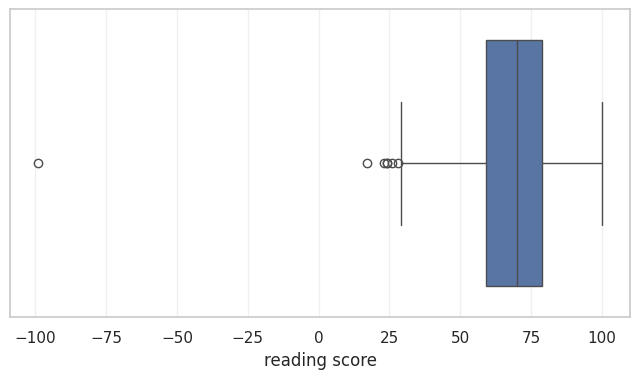

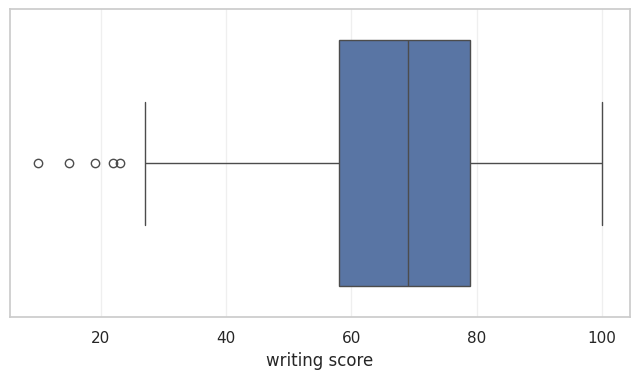

In [ ]:
sns.boxplot(x=df["math score"])
plt.show()
sns.boxplot(x=df["reading score"])
plt.show()
sns.boxplot(x=df_clean["writing score"])
plt.show()

## Draft 3 Problems
- Two of the three boxplots were drawn from the raw data `df`, so impossible values such as −10 and −99 appeared as outliers.
- The plots used different data sources (raw and cleaned), so they were not consistent with each other.
- Each subject was drawn in a separate figure with its own scale, so the subjects could not be compared directly.
- No colours were used to distinguish the subjects.
- No titles were added, and the axis labels showed only the column names without units.
- No interpretation of the findings was given.

## Improvement: Draft 3

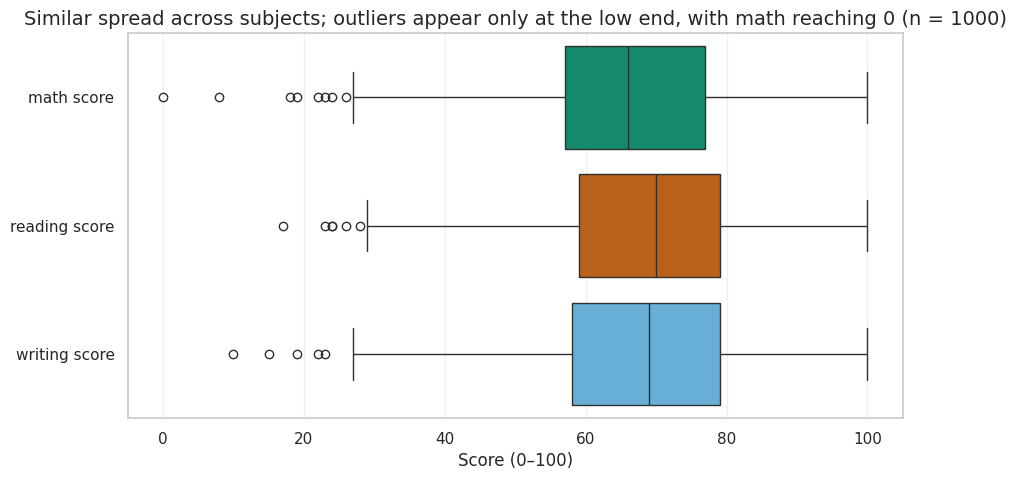

- All boxplots were drawn from the cleaned data, so the impossible values (−10 and −99) no longer appear.
- The three subjects were placed in one figure on a shared axis so their medians and spreads can be compared directly.
- Each subject was given its own colour from Part A so the subject colours stay consistent across all plots.
- A takeaway title was added stating that the spread is similar across subjects and that outliers appear only at the low end.
- The axis was labelled "Score (0–100)" so the unit is clear.

> The improved version is the same figure shown in Part B. You can go back to see the code.

# Part F — Advanced Visualization & Dashboard
**Responsible:** Aljawharah Alsaadi  

* Final dashboard: which background factor is most strongly associated with student scores?

  View 1 (top-left, the main view) ranks the factors by the gap between their highest and lowest scoring group, with the largest in blue. The Factor menu changes views 2–4 together: the score distribution per group, the mean of each subject per group, and the number of students per group. View 4 lets the reader judge how reliable each group mean is.

* Interpretation

  * Answer to the question: by the size of the gap, parental education is first (10.6 points), followed by race/ethnicity (9.8), lunch (8.6), test preparation (7.6) and gender (3.8).

  * Reliability (view 4): the two largest gaps rest on the smallest groups. The master’s-degree group has only 59 students (mean 73.8, against 63.1 for “high school”), and group A has only 89 (mean 63.0, against 72.8 for group E). The gap is a max-min measure, so small groups can inflate it. This is why the ANOVA effect sizes in Part D matter: parental education explains about 5.2% of the variance and race/ethnicity about 3.6%.

  * Subject view (view 3): lunch has its largest effect in math (standard 69.9 vs free/reduced 58.9, an 11-point gap). Gender shows opposite directions that the average hides. Females score higher in reading (72.6 vs 65.4) and writing (72.5 vs 63.3), while males score higher in math (68.8 vs 63.7).

  * Test preparation: the course gap (7.6 points) is smaller than the parental-education gap, but it is based on larger groups (358 vs 642) and is the only factor that a school can change.

So what? No single background factor dominates. The largest gaps are about 10 points on a 0–100 scale, and each factor explains only a small share of the variance.

In [ ]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from matplotlib.colors import to_hex

# 1) Factors shown in the dashboard: column -> (label, colours, category order)
factors = {
    'test preparation course':     ('Test preparation',   tp_colours,     ['none', 'completed']),
    'lunch':                       ('Lunch',              lunch_colours,  ['free/reduced', 'standard']),
    'gender':                      ('Gender',             gender_colours, ['female', 'male']),
    'parental level of education': ('Parental education', edu_colors,    edu_order),
    'race/ethnicity':              ('Race/ethnicity',     race_colours,   race_order),
}

# 2) Ranking metric: gap between the highest and lowest group mean of the average score
gaps = {}
for col, (label, colours, order) in factors.items():
    group_means = df_clean.groupby(col)['average score'].mean()
    gaps[label] = group_means.max() - group_means.min()
gaps = pd.Series(gaps).sort_values() # sorted -> largest bar on top
top_factor = gaps.idxmax()

# 3) Dashboard grid: 2 x 2, most important view top-left
fig = make_subplots(
    rows=2, cols=2, vertical_spacing=0.24, horizontal_spacing=0.12,
    subplot_titles=('Score gap between groups (points)',
                    'Average score by group',
                    'Mean score by subject and group',
                    'Number of students per group (sample size)'))

# View 1 (always visible): which factor has the largest gap?
fig.add_trace(go.Bar(
    x=gaps.values, y=gaps.index, orientation='h',
    marker_color=[ACCENT if f == top_factor else NEUTRAL for f in gaps.index],
    text=[f'{v:.1f}' for v in gaps.values], textposition='outside',
    hovertemplate='%{y}: %{x:.1f} points<extra></extra>', showlegend=False), row=1, col=1)

owner = ['always']  # which factor each trace belongs to

# Views 2-4: one set of traces per factor (only the first factor is visible at start)
for i, (col, (label, colours, order)) in enumerate(factors.items()):
    visible = (i == 0)
    colour_map = {k: to_hex(v) for k, v in colours.items()}

    # View 2: distribution of the average score per group
    box = px.box(df_clean, x=col, y='average score', color=col,
                 color_discrete_map=colour_map, category_orders={col: order})
    for tr in box.data:
        tr.visible = visible; tr.showlegend = False
        fig.add_trace(tr, row=1, col=2)
        owner.append(col)

    # View 3: mean of each subject per group (colour = subject, same as the rest of the report)
    means = (df_clean.groupby(col)[score_cols].mean().reindex(order)
             .reset_index().melt(id_vars=col, var_name='subject', value_name='mean score'))
    bars = px.bar(means, x=col, y='mean score', color='subject', barmode='group',
                  color_discrete_map=subject_colours, category_orders={col: order})
    for tr in bars.data:
        tr.visible = visible
        tr.hovertemplate = '%{x}<br>' + tr.name + ': %{y:.1f}<extra></extra>'
        fig.add_trace(tr, row=2, col=1)
        owner.append(col)

    # View 4: group sizes, so the reader knows how reliable each group mean is
    counts = df_clean[col].value_counts().reindex(order).reset_index()
    count_bars = px.bar(counts, x=col, y='count', color=col, text='count',
                        color_discrete_map=colour_map, category_orders={col: order})
    for tr in count_bars.data:
        tr.visible = visible; tr.showlegend = False
        fig.add_trace(tr, row=2, col=2)
        owner.append(col)

#4) Dropdown: choose the factor; views 2-4 update together
buttons = []
for col, (label, colours, order) in factors.items():
    buttons.append(dict(
        label=label, method='update',
        args=[{'visible': [o == 'always' or o == col for o in owner]},
              {'xaxis2.title.text': label, 'xaxis3.title.text': label, 'xaxis4.title.text': label}]))

fig.update_layout(
    updatemenus=[dict(buttons=buttons, direction='down', x=1.0, xanchor='right', y=1.13, yanchor='top',
                      showactive=True)],
    title=dict(text=f'Which background factor is most strongly associated with student scores?<br>'
                    f'<sup>{top_factor} shows the largest gap between groups; use the menu to inspect each factor '
                    f'(n = {len(df_clean)})</sup>', x=0.02),
    template='simple_white', height=920, width=1200, barmode='group',
    legend=dict(title='Subject', orientation='h', x=0.0, y=-0.2),
    annotations=list(fig.layout.annotations) + [dict(text='Factor:', x=0.8, xref='paper', y=1.12,
                                                       yref='paper', showarrow=False, xanchor='right')])

# Axis labels with units; fixed 0-100 range so the scale does not jump when the factor changes
fig.update_xaxes(title_text='Gap in average score (points)', row=1, col=1)
fig.update_yaxes(title_text='Average score (0–100)', range=[0, 100], row=1, col=2)
fig.update_yaxes(title_text='Mean score (0–100)', range=[0, 100], row=2, col=1)
fig.update_yaxes(title_text='Number of students', row=2, col=2)
first_label = list(factors.values())[0][0]
for c in [(1, 2), (2, 1), (2, 2)]:
    fig.update_xaxes(title_text=first_label, row=c[0], col=c[1])
fig.update_traces(cliponaxis=False, textposition='outside', selector=dict(type='bar'))

fig.show()

# Part G — Conclusions
**Responsible:** Maryam Ajabnoor  

> All background factors studied were associated with students' scores, but each one explains only a small part of the variation. Test preparation and standard lunch were linked to higher scores, parental education showed the largest gap between groups, and gender was linked in opposite directions depending on the subject (males higher in math, females higher in reading and writing). No single factor dominates.
----
| Hypothesis | Test | Result |
|---|---|---|
| H1: Test preparation is associated with the average score | t-test (t = 8.41) | H0 rejected, p < 0.001 |
| H2: Parental education is associated with the average score | ANOVA | H0 rejected, p < 0.001 (small effect) |
| H3: Race/ethnicity is associated with the average score | ANOVA | H0 rejected, p < 0.001 (small effect) |
---
**Limitation:** The dashboard ranks factors by the max–min gap, which can be inflated by small groups and by factors with more categories.

# References

- *Chart visualization — pandas 3.1.1 documentation.* (n.d.). Retrieved November 18, 2026, from https://pandas.pydata.org/docs/user_guide/visualization.html

- Chugani, V. (2024, November 25). *How to Conduct One-Way ANOVA in Python Using Pingouin.* Statology. Retrieved November 18, 2026, from https://www.statology.org/how-to-conduct-one-way-anova-in-python-using-pingouin/

- *Examples — Matplotlib 3.11.2 documentation.* (n.d.). Retrieved November 18, 2026, from https://matplotlib.org/stable/gallery/index.html

- *How to add data labels to Seaborn Countplot / Factorplot [duplicate].* (2023, February 19). Stack Overflow. Retrieved November 18, 2026, from https://stackoverflow.com/questions/49044131/how-to-add-data-labels-to-seaborn-countplot-factorplot

- *Order categories by count in a countplot.* (2023, December 19). Stack Overflow. Retrieved November 18, 2026, from https://stackoverflow.com/questions/46623583/order-categories-by-count-in-a-countplot

- *Plotly for Data Visualization in Python.* (2026, April 28). GeeksforGeeks. Retrieved November 18, 2026, from https://www.geeksforgeeks.org/data-visualization/using-plotly-for-interactive-data-visualization-in-python/

- *Seaborn.set_theme — Seaborn 0.13.2 documentation.* (n.d.). Seaborn. Retrieved November 18, 2026, from https://seaborn.pydata.org/generated/seaborn.set_theme.html

- *T-test.* (2026, April 8). GeeksforGeeks. Retrieved November 18, 2026, from https://www.geeksforgeeks.org/data-science/t-test/

- Thevapalan, A. (2024, September 20). *ANOVA Test: An In-Depth Guide with Examples.* DataCamp. Retrieved November 18, 2026, from https://www.datacamp.com/tutorial/anova-test

- *User guide and tutorial — Seaborn 0.13.2 documentation.* (n.d.). Retrieved November 18, 2026, from https://seaborn.pydata.org/tutorial.html

- VanderPlas, J. (2016, November). *Python Data Science Handbook.* Retrieved November 18, 2026, from https://jakevdp.github.io/PythonDataScienceHandbook